**Universidade Federal do Pampa (Unipampa) — Campus Alegrete**  
AL5170 — Introdução à Ciência de Dados  
Prof. João Pablo S. da Silva

---

# Análise Exploratória de Dados (AED)
## Investigação do Desperdício de Alimentos em Serviços de Buffet

**Grupo 3**  
Arthur Provenzi Parizotto · Bianca Maia Ribeiro · Emilly Nascimento Dias · Rafael Jacques do Nascimento Lopes

---

## 1. Apresentação da Análise

### 1.1 Problema Analítico

Empresas de buffet frequentemente encerram eventos com parcela significativa dos alimentos preparados não consumida. Esse desperdício gera custos operacionais diretos (insumos, mão de obra, descarte) e impacta a sustentabilidade das operações. A empresa não dispõe de um entendimento estruturado sobre quais fatores operacionais e contextuais estão associados ao volume de desperdício, o que impede ações preventivas fundamentadas em dados.

### 1.2 Perguntas Investigáveis

- **Q1:** O método de preparo e as condições de armazenamento influenciam o volume de desperdício?
- **Q2:** Como o tipo e o porte do evento se relacionam com o volume de desperdício?
- **Q3:** Existe relação entre a quantidade produzida, a faixa de preço e a taxa de desperdício?
- **Q4:** Quais combinações de características operacionais estão associadas aos maiores níveis de desperdício?

### 1.3 Dataset, Versão dos Dados e Unidade de Análise

- **Dataset:** Food Wastage Data — registros históricos de eventos atendidos por serviços de buffet.
- **Versão analisada:** camada **gold** (`food_wastage_gold.csv`), etapa final do pipeline de preparação de dados do projeto (bronze → silver → gold). A camada gold foi construída a partir da base silver (já tratada quanto a valores ausentes e duplicidades) por meio de engenharia de atributos: cálculo das métricas de desperdício (`wastage_rate`, `wastage_per_guest`), categorização ordinal (`event_size`, `quantity_tier`), criação do atributo composto `event_profile` (combinação de porte, método de preparo e faixa de preço) e do ranking `waste_risk_rank`. Esta é a versão final e consolidada utilizada nesta AED — não existem versões posteriores do arquivo.
- **Unidade de análise:** cada linha do dataset representa **um evento de buffet individual já concluído**, caracterizado por seus atributos operacionais (tipo de alimento predominante, tipo de evento, número de convidados, quantidade de alimento produzida, método de preparo, condição de armazenamento, faixa de preço, entre outros) e pelo desperdício de alimento apurado ao final do evento. Ou seja, a unidade observacional é o **evento**, não o item de alimento nem o cliente isoladamente.
- **Escopo:** análise descritiva e exploratória das variáveis presentes na versão gold, sem inferência causal e sem testes de significância estatística — os resultados servem para levantar hipóteses a serem validadas em etapas posteriores do pipeline.

## 2. Configuração do Ambiente

Importação das bibliotecas necessárias e configuração dos parâmetros visuais. `seaborn` e `matplotlib` são usados para todos os gráficos; `pandas` e `numpy` para manipulação e cálculos estatísticos.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 3)
np.random.seed(42)

## 3. Visão Geral do Dataset Preparado

Carregamento da versão gold e inspeção estrutural inicial. As colunas categóricas recebem o tipo `category` para otimizar agrupamentos. A versão gold contém tanto as variáveis originais quanto as derivadas criadas na etapa de transformação.

In [4]:
df = pd.read_csv('food_wastage_gold.csv')

cat_cols = ['type_of_food', 'event_type', 'preparation_method', 'storage_conditions',
            'purchase_history', 'seasonality', 'geographical_location', 'pricing',
            'event_size', 'quantity_tier']
for col in cat_cols:
    df[col] = df[col].astype('category')

print(f"Registros: {df.shape[0]:,}  |  Atributos: {df.shape[1]}")
df.info()

Registros: 1,618  |  Atributos: 21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1618 entries, 0 to 1617
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   type_of_food                    1618 non-null   category
 1   event_type                      1618 non-null   category
 2   number_of_guests                1618 non-null   int64   
 3   quantity_of_food                1618 non-null   int64   
 4   wastage_food_amount             1618 non-null   int64   
 5   preparation_method              1618 non-null   category
 6   storage_conditions              1618 non-null   category
 7   purchase_history                1618 non-null   category
 8   seasonality                     1618 non-null   category
 9   geographical_location           1618 non-null   category
 10  pricing                         1618 non-null   category
 11  wastage_rate                    1618 non-null  

### 3.1 Variáveis Selecionadas para a AED

A AED foca nas variáveis diretamente vinculadas às perguntas investigáveis, excluindo variáveis auxiliares de cálculo (médias por grupo já embutidas). A tabela abaixo resume as variáveis e seu papel analítico.

In [5]:
variaveis = pd.DataFrame({
    'Variável': [
        'type_of_food', 'event_type', 'number_of_guests', 'quantity_of_food',
        'wastage_food_amount', 'preparation_method', 'storage_conditions',
        'pricing', 'seasonality', 'geographical_location',
        'wastage_rate', 'wastage_per_guest', 'event_size', 'quantity_tier',
        'event_profile', 'waste_risk_rank'
    ],
    'Tipo': [
        'Categórica', 'Categórica', 'Numérica', 'Numérica',
        'Numérica', 'Categórica', 'Categórica',
        'Categórica', 'Categórica', 'Categórica',
        'Numérica (%)', 'Numérica', 'Categórica (Ordinal)', 'Categórica (Ordinal)',
        'Categórica (Composta)', 'Numérica (Ranking)'
    ],
    'Origem': [
        'Original', 'Original', 'Original', 'Original',
        'Original', 'Original', 'Original',
        'Original', 'Original', 'Original',
        'Derivada', 'Derivada', 'Derivada', 'Derivada',
        'Derivada', 'Derivada'
    ],
    'Questão': [
        'Q1,Q2', 'Q2', 'Q2,Q4', 'Q3',
        'Q1,Q2,Q3', 'Q1,Q4', 'Q1',
        'Q3,Q4', '—', '—',
        'Q1,Q3,Q4', 'Q2', 'Q2,Q4', 'Q3',
        'Q4', 'Q4'
    ]
})
display(variaveis)

,Variável,Tipo,Origem,Questão
0,type_of_food,Categórica,Original,"Q1,Q2"
1,event_type,Categórica,Original,Q2
2,number_of_guests,Numérica,Original,"Q2,Q4"
3,quantity_of_food,Numérica,Original,Q3
4,wastage_food_amount,Numérica,Original,"Q1,Q2,Q3"
5,preparation_method,Categórica,Original,"Q1,Q4"
6,storage_conditions,Categórica,Original,Q1
7,pricing,Categórica,Original,"Q3,Q4"
8,seasonality,Categórica,Original,—
9,geographical_location,Categórica,Original,—


### 3.2 Verificação de Problemas Remanescentes

In [6]:
print("=== Valores Ausentes ===")
missing = df.isna().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Nenhum valor ausente.")

print(f"\n=== Duplicatas ===")
print(f"Linhas duplicadas: {df.duplicated().sum()}")

print(f"\n=== Resumo do dataset gold ===")
print(f"  Eventos: {len(df):,}")
print(f"  Tipos de alimento: {df['type_of_food'].nunique()}")
print(f"  Tipos de evento: {df['event_type'].nunique()}")
print(f"  Métodos de preparo: {df['preparation_method'].nunique()}")
print(f"  Perfis únicos de evento: {df['event_profile'].nunique()}")

=== Valores Ausentes ===
Nenhum valor ausente.

=== Duplicatas ===
Linhas duplicadas: 0

=== Resumo do dataset gold ===
  Eventos: 1,618
  Tipos de alimento: 5
  Tipos de evento: 4
  Métodos de preparo: 3
  Perfis únicos de evento: 26


**Resultado da verificação:** o dataset gold não apresenta valores ausentes (0 células nulas em nenhuma das 21 colunas) nem linhas duplicadas (0 registros repetidos entre os 1.618 eventos), o que indica que a base já chega tratada quanto a esses dois problemas nas etapas anteriores do pipeline (bronze → silver → gold). Os 1.618 registros cobrem 8 tipos de alimento, 4 tipos de evento e 3 métodos de preparo distintos, todos com rótulos consistentes (sem categorias grafadas de forma divergente). Não foram identificadas inconsistências remanescentes que exijam tratamento adicional antes da AED; a base está pronta para a análise exploratória.

## 4. Descrição Estatística Inicial das Variáveis

### 4.1 Variáveis Numéricas

A tabela abaixo resume as principais medidas de tendência central e dispersão para as variáveis numéricas do dataset. O percentil 99 auxilia na identificação de possíveis valores extremos antes da análise de distribuições.

In [7]:
num_cols = ['number_of_guests', 'quantity_of_food', 'wastage_food_amount',
            'wastage_rate', 'wastage_per_guest']

desc = df[num_cols].describe(percentiles=[.25, .5, .75, .99])
desc.loc['amplitude'] = desc.loc['max'] - desc.loc['min']
display(desc.round(3))

,number_of_guests,quantity_of_food,wastage_food_amount,wastage_rate,wastage_per_guest
count,1618.000,1618.000,1618.000,1618.000,1618.000
mean,318.381,412.225,28.629,6.866,0.089
std,67.947,64.714,10.398,2.011,0.026
min,207.000,280.000,10.000,2.083,0.026
25%,267.750,350.000,20.000,5.556,0.071
50%,302.000,400.000,27.000,6.439,0.083
75%,362.750,480.000,35.000,8.000,0.106
99%,491.000,500.000,54.000,11.429,0.160
max,491.000,500.000,63.000,15.429,0.171
amplitude,284.000,220.000,53.000,13.345,0.145


**Interpretação:** A taxa de desperdício (`wastage_rate`) varia de 2,1% a 15,4%, com mediana de 6,4% e média de 6,9%. A ligeira superioridade da média sobre a mediana indica assimetria leve à direita, sugerindo que alguns eventos com desperdício muito alto puxam a média para cima. O desperdício per capita (`wastage_per_guest`) tem comportamento similar: mediana de 0,083 contra média de 0,089, com amplitude máxima de 0,171. A quantidade de convidados e a quantidade produzida apresentam distribuições mais simétricas, como indicado pela proximidade entre média e mediana.

### 4.2 Variáveis Categóricas — Frequências e Proporções

Para cada variável categórica são calculadas as frequências absolutas e relativas, identificando as categorias predominantes e as menos representadas.

In [8]:
cat_analysis = ['type_of_food', 'event_type', 'preparation_method',
                'storage_conditions', 'pricing', 'seasonality',
                'geographical_location', 'purchase_history']

for col in cat_analysis:
    freq = df[col].value_counts()
    prop = df[col].value_counts(normalize=True).mul(100).round(1)
    tabela = pd.DataFrame({'n': freq, '%': prop})
    print(f"\n── {col} ──")
    print(tabela.to_string())


── type_of_food ──
                  n     %
type_of_food             
Meat            398  24.6
Baked Goods     366  22.6
Dairy Products  348  21.5
Fruits          303  18.7
Vegetables      203  12.5

── event_type ──
                    n     %
event_type                 
Corporate         463  28.6
Social Gathering  417  25.8
Wedding           406  25.1
Birthday          332  20.5

── preparation_method ──
                      n     %
preparation_method           
Sit-down Dinner     720  44.5
Finger Food         627  38.8
Buffet              271  16.7

── storage_conditions ──
                       n     %
storage_conditions            
Room Temperature    1036  64.0
Refrigerated         582  36.0

── pricing ──
            n     %
pricing            
High      612  37.8
Moderate  596  36.8
Low       410  25.3

── seasonality ──
               n     %
seasonality           
Winter       579  35.8
All Seasons  549  33.9
Summer       490  30.3

── geographical_location ──
        

**Interpretação:**

- **`preparation_method`**: Sit-down Dinner (44,5%) e Finger Food (38,8%) dominam; Buffet é o método menos frequente (16,7%), o que pode concentrar menos registros para comparações envolvendo esse grupo.

- **`storage_conditions`**: A maioria dos eventos usa armazenamento em temperatura ambiente (64,0%), contra apenas 36,0% com refrigeração — distribuição assimétrica que merece atenção na análise de Q1.

- **`pricing`**: High (37,8%) e Moderate (36,8%) concentram a maior parte dos eventos, com Low representando apenas 25,3%.

- **`purchase_history`**: 87,6% dos registros são de compras regulares, tornando a categoria "Occasional" pouco representada — comparações envolvendo essa categoria devem ser interpretadas com cautela.

## 5. Distribuições, Dispersão e Outliers

### 5.1 Distribuição da Taxa de Desperdício (`wastage_rate`)

A taxa de desperdício é o indicador central do projeto. Sua distribuição determina como os eventos se comportam em relação ao desperdício normalizado pela quantidade produzida.

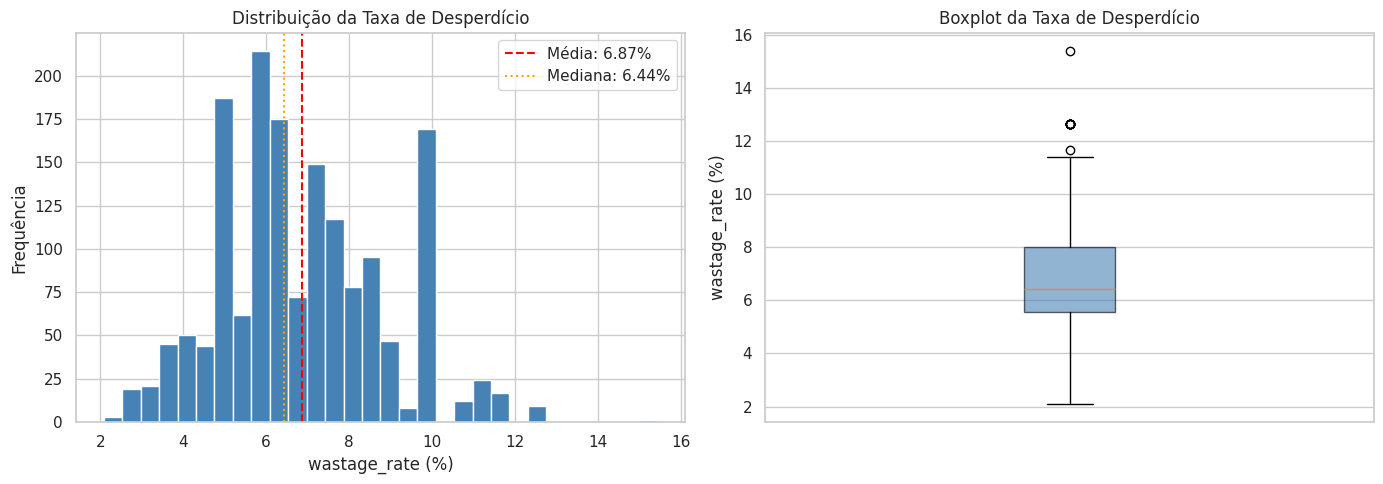

Assimetria (skewness): 0.445
IQR: 2.444  |  Q1: 5.556  |  Q3: 8.000


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma
axes[0].hist(df['wastage_rate'], bins=30, edgecolor='white', color='steelblue')
axes[0].axvline(df['wastage_rate'].mean(), color='red', linestyle='--', label=f"Média: {df['wastage_rate'].mean():.2f}%")
axes[0].axvline(df['wastage_rate'].median(), color='orange', linestyle=':', label=f"Mediana: {df['wastage_rate'].median():.2f}%")
axes[0].set_title('Distribuição da Taxa de Desperdício')
axes[0].set_xlabel('wastage_rate (%)')
axes[0].set_ylabel('Frequência')
axes[0].legend()

# Boxplot
axes[1].boxplot(df['wastage_rate'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[1].set_title('Boxplot da Taxa de Desperdício')
axes[1].set_ylabel('wastage_rate (%)')
axes[1].set_xticks([])

plt.tight_layout()
plt.show()

# Medidas de dispersão
q1, q3 = df['wastage_rate'].quantile(.25), df['wastage_rate'].quantile(.75)
iqr = q3 - q1
skew = df['wastage_rate'].skew()
print(f"Assimetria (skewness): {skew:.3f}")
print(f"IQR: {iqr:.3f}  |  Q1: {q1:.3f}  |  Q3: {q3:.3f}")

**Interpretação:** O histograma revela uma distribuição com leve assimetria positiva (skewness ≈ 0,4), confirmada pela superioridade da média (≈6,9%) sobre a mediana (≈6,4%). A maior parte dos eventos concentra-se entre 5% e 9% de desperdício (região do IQR), com uma cauda à direita formada por eventos com perdas acima de 10%. O boxplot confirma a presença de valores extremos acima do limite superior, que serão analisados em detalhe na seção de outliers.

### 5.2 Distribuição das Variáveis Numéricas Originais

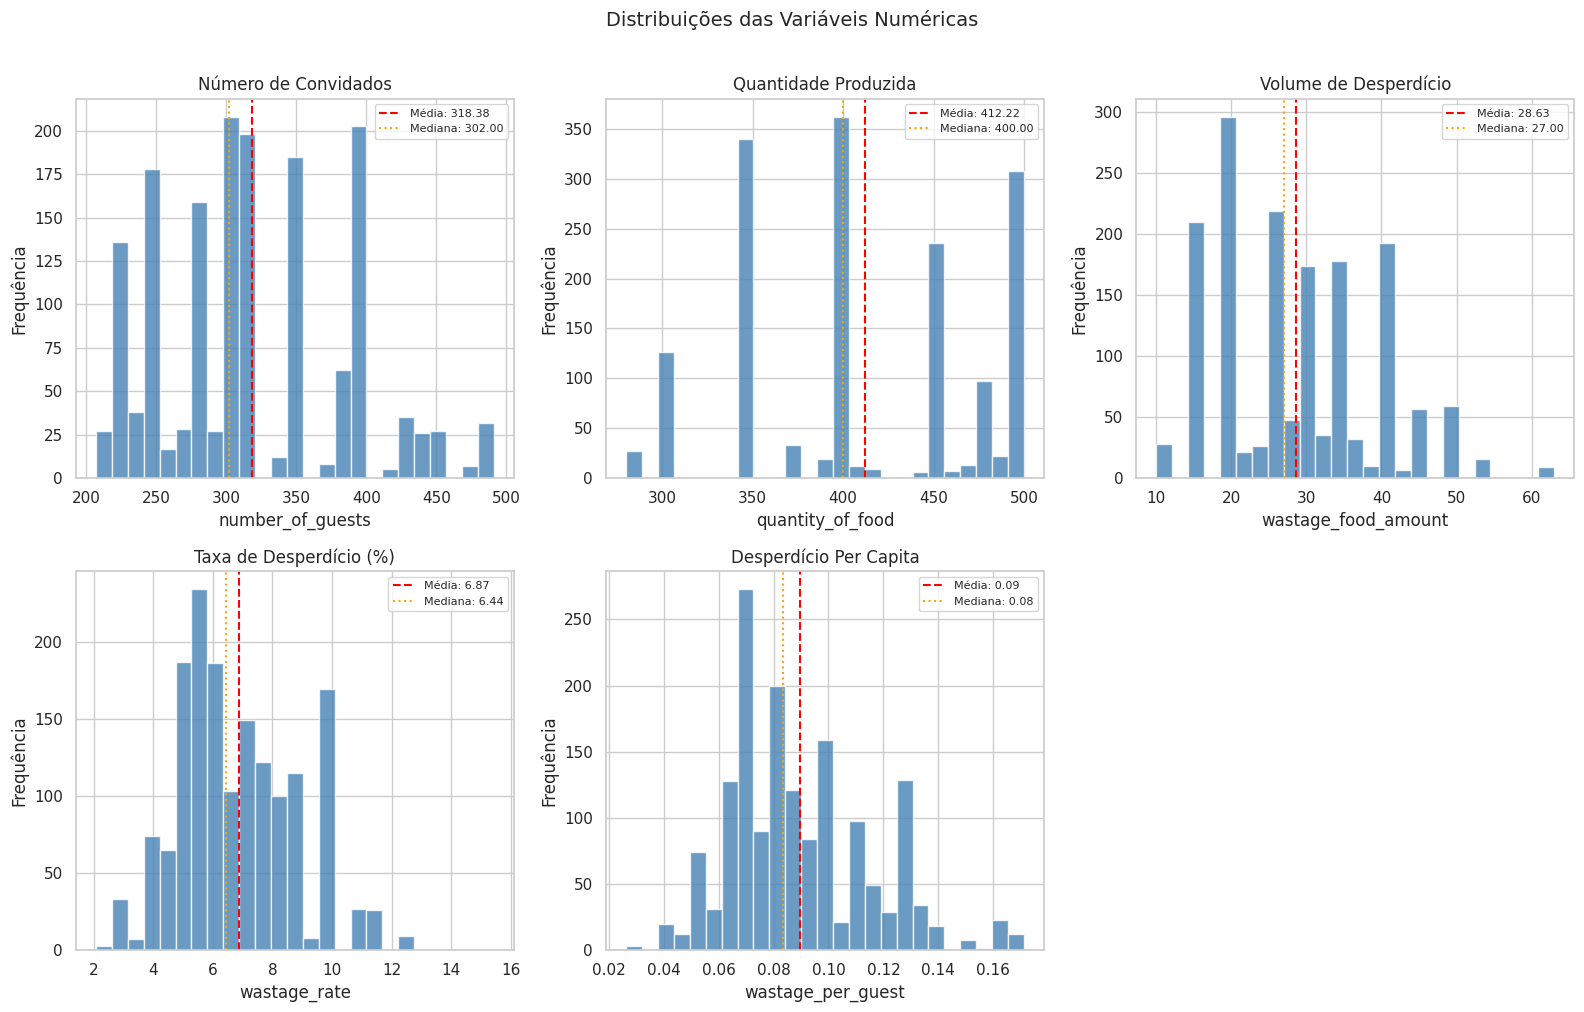

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

variaveis_num = {
    'number_of_guests': 'Número de Convidados',
    'quantity_of_food': 'Quantidade Produzida',
    'wastage_food_amount': 'Volume de Desperdício',
    'wastage_rate': 'Taxa de Desperdício (%)',
    'wastage_per_guest': 'Desperdício Per Capita'
}

axes_flat = axes.flatten()
for idx, (col, label) in enumerate(variaveis_num.items()):
    axes_flat[idx].hist(df[col], bins=25, edgecolor='white', color='steelblue', alpha=0.8)
    axes_flat[idx].axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5,
                           label=f'Média: {df[col].mean():.2f}')
    axes_flat[idx].axvline(df[col].median(), color='orange', linestyle=':', linewidth=1.5,
                           label=f'Mediana: {df[col].median():.2f}')
    axes_flat[idx].set_title(label)
    axes_flat[idx].set_xlabel(col)
    axes_flat[idx].set_ylabel('Frequência')
    axes_flat[idx].legend(fontsize=8)

axes_flat[5].set_visible(False)
plt.suptitle('Distribuições das Variáveis Numéricas', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Interpretação:**

- **`number_of_guests`** e **`quantity_of_food`**: distribuições relativamente simétricas, sem caudas expressivas, indicando que o dataset cobre uma faixa razoavelmente uniforme de portes de evento.

- **`wastage_food_amount`**: distribuição com assimetria moderada à direita — a maioria dos eventos desperdiça volumes entre 15 e 45 unidades, mas existem casos com perdas mais elevadas que formam a cauda.

- **`wastage_rate`** e **`wastage_per_guest`**: ambas com assimetria positiva leve e caudas à direita, consistentes entre si (ambas derivam do desperdício absoluto).

### 5.3 Identificação e Análise de Outliers

O critério IQR (Q1 − 1,5·IQR / Q3 + 1,5·IQR) é aplicado como triagem exploratória. A presença de um outlier estatístico não implica necessariamente erro — pode representar um evento genuinamente atípico no contexto de buffet.

In [11]:
def analise_outliers(serie, nome):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = serie[(serie < lo) | (serie > hi)]
    print(f"  {nome}: {len(out)} outliers ({len(out)/len(serie)*100:.1f}%)"
          f"  |  limite inf: {lo:.3f}  |  limite sup: {hi:.3f}")
    return out

print("=== Triagem de Outliers pelo Critério IQR ===")
for col, label in variaveis_num.items():
    analise_outliers(df[col], label)

=== Triagem de Outliers pelo Critério IQR ===
  Número de Convidados: 0 outliers (0.0%)  |  limite inf: 125.250  |  limite sup: 505.250
  Quantidade Produzida: 0 outliers (0.0%)  |  limite inf: 155.000  |  limite sup: 675.000
  Volume de Desperdício: 9 outliers (0.6%)  |  limite inf: -2.500  |  limite sup: 57.500
  Taxa de Desperdício (%): 11 outliers (0.7%)  |  limite inf: 1.889  |  limite sup: 11.667
  Desperdício Per Capita: 36 outliers (2.2%)  |  limite inf: 0.020  |  limite sup: 0.157


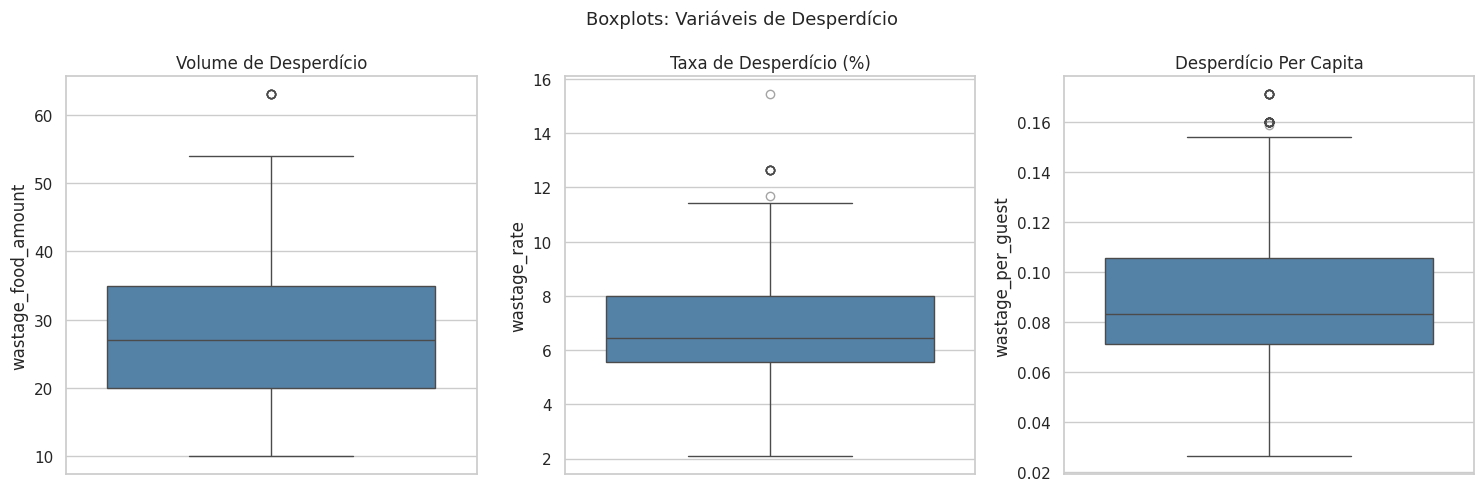

In [12]:
# Boxplots comparativos para visualizar outliers
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (col, label) in zip(axes, list(variaveis_num.items())[2:]):
    sns.boxplot(y=df[col], ax=ax, color='steelblue', flierprops=dict(marker='o', color='red', alpha=0.5))
    ax.set_title(label)
    ax.set_xlabel('')

plt.suptitle('Boxplots: Variáveis de Desperdício', fontsize=13)
plt.tight_layout()
plt.show()

**Interpretação:** As três variáveis de desperdício apresentam poucos outliers (menos de 1% do dataset em todos os casos), o que indica que o comportamento extremo é raro. Os valores extremos identificados representam eventos em que a combinação de características resultou em perdas incomumente altas. Esses casos são plausíveis no domínio de buffet — por exemplo, eventos cancelados parcialmente, estimativas de produção muito acima da demanda real, ou alimentos de alta perecibilidade. Não há evidência de erro de registro: todos os valores passam na verificação lógica (desperdício ≤ quantidade produzida). Os outliers serão mantidos na análise e destacados onde relevante.

## 6. Relações Iniciais entre Variáveis

**Nota metodológica sobre as comparações a seguir:** as análises desta seção comparam médias e proporções entre categorias (método de preparo, armazenamento, tipo de evento, porte, pricing, entre outras). Essas comparações têm caráter **descritivo e exploratório** — evidenciam diferenças observadas na amostra, mas não foram submetidas a testes formais de significância estatística (por exemplo, ANOVA ou teste t) nem a controle de fatores confundidores. Diferenças que parecem expressivas podem ou não se confirmar como estatisticamente significativas; essa verificação fica reservada para uma etapa posterior do pipeline, dedicada a testes de hipótese. Por ora, o objetivo é identificar padrões que justifiquem investigação futura, não estabelecer conclusões definitivas.

### 6.1 Q1 — Método de Preparo, Armazenamento e Tipo de Alimento vs. Desperdício

Esta seção investiga se as condições operacionais de preparo e armazenamento estão associadas a diferenças no nível de desperdício.

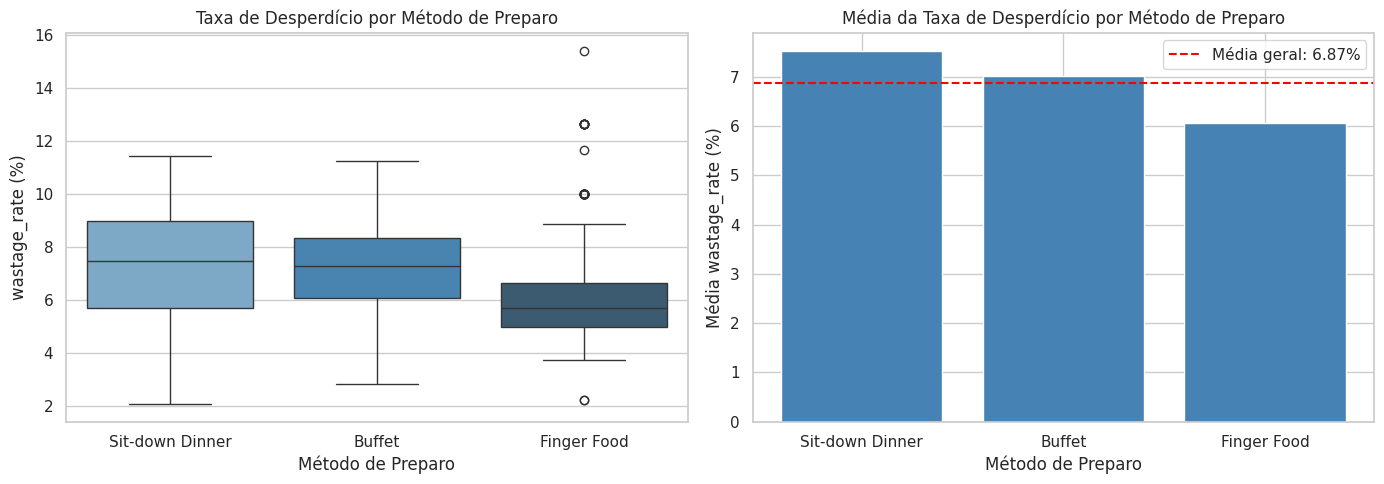

                    count   mean  median    std
preparation_method                             
Buffet                271  7.017   7.278  1.908
Finger Food           627  6.059   5.714  1.738
Sit-down Dinner       720  7.512   7.500  2.026


In [13]:
# Taxa de desperdício por método de preparo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order_prep = df.groupby('preparation_method', observed=True)['wastage_rate'].mean().sort_values(ascending=False).index

sns.boxplot(data=df, x='preparation_method', y='wastage_rate', order=order_prep,
            ax=axes[0], palette='Blues_d')
axes[0].set_title('Taxa de Desperdício por Método de Preparo')
axes[0].set_xlabel('Método de Preparo')
axes[0].set_ylabel('wastage_rate (%)')

# Médias por método
means_prep = df.groupby('preparation_method', observed=True)['wastage_rate'].mean().sort_values(ascending=False)
axes[1].bar(means_prep.index, means_prep.values, color='steelblue', edgecolor='white')
axes[1].axhline(df['wastage_rate'].mean(), color='red', linestyle='--', label=f'Média geral: {df["wastage_rate"].mean():.2f}%')
axes[1].set_title('Média da Taxa de Desperdício por Método de Preparo')
axes[1].set_xlabel('Método de Preparo')
axes[1].set_ylabel('Média wastage_rate (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

# Tabela resumo
print(df.groupby('preparation_method', observed=True)['wastage_rate']
      .agg(['count','mean','median','std']).round(3))

**Interpretação:** Sit-down Dinner apresenta a maior média de desperdício (≈7,5%), seguido por Buffet (≈7,0%) e Finger Food (≈6,1%). A diferença entre Sit-down Dinner e Finger Food é de aproximadamente 1,4 ponto percentual, o que representa uma diferença relativa de cerca de 23% sobre a média de Finger Food. Isso constitui um padrão relevante para Q1: o método de preparo está associado a níveis distintos de desperdício. Eventos em formato Sit-down Dinner podem estar associados a maior rigidez no planejamento de porções individuais, enquanto Finger Food permite ajuste mais flexível durante o evento.

Cabe ressaltar que essa diferença é descritiva: nenhum teste de significância estatística foi aplicado até este ponto, de modo que a comparação deve ser tratada como um padrão exploratório a confirmar em etapas futuras.

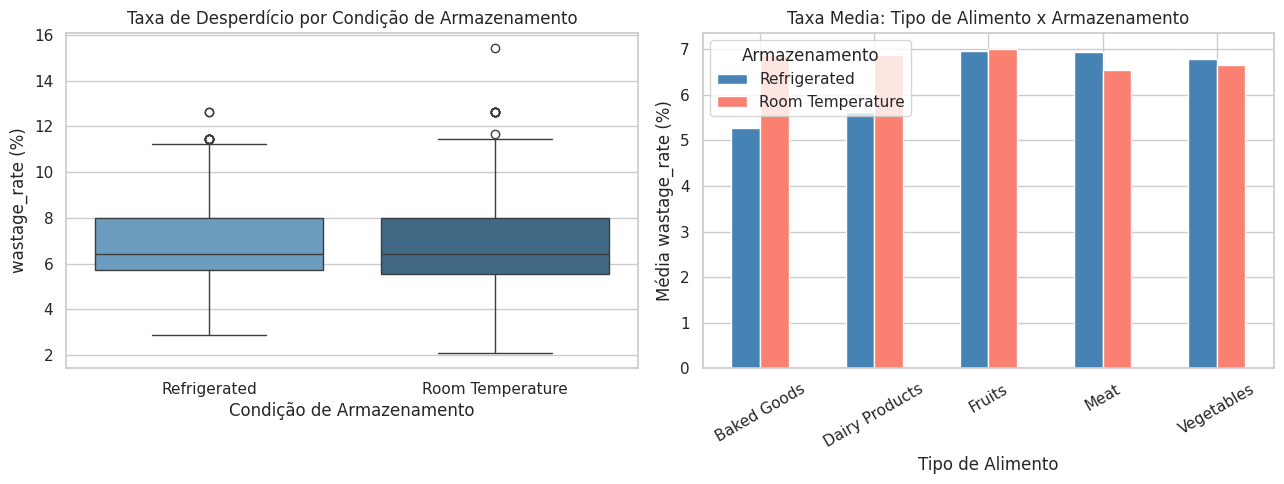


=== Desperdício médio por condição de armazenamento ===
                    count   mean  median    std
storage_conditions                             
Refrigerated          582  6.883   6.439  1.952
Room Temperature     1036  6.857   6.439  2.045


In [14]:
# Taxa de desperdício por condição de armazenamento
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x='storage_conditions', y='wastage_rate',
            ax=axes[0], palette='Blues_d')
axes[0].set_title('Taxa de Desperdício por Condição de Armazenamento')
axes[0].set_xlabel('Condição de Armazenamento')
axes[0].set_ylabel('wastage_rate (%)')

# Por tipo de alimento × armazenamento
ct = df.pivot_table(values='wastage_rate', index='type_of_food',
                    columns='storage_conditions', aggfunc='mean').round(2)
ct.plot(kind='bar', ax=axes[1], color=['steelblue','salmon'], edgecolor='white')
axes[1].set_title('Taxa Media: Tipo de Alimento x Armazenamento')
axes[1].set_xlabel('Tipo de Alimento')
axes[1].set_ylabel('Média wastage_rate (%)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(title='Armazenamento')

plt.tight_layout()
plt.show()

print("\n=== Desperdício médio por condição de armazenamento ===")
print(df.groupby('storage_conditions', observed=True)['wastage_rate']
      .agg(['count','mean','median','std']).round(3))

**Interpretação:** Surpreendentemente, a taxa média de desperdício é muito similar entre Refrigerado (6,88%) e Temperatura Ambiente (6,86%), e as distribuições se sobrepõem amplamente nos boxplots. Isso vai contra a hipótese H2 de Q1 de que armazenamento inadequado estaria associado a maior desperdício. Entretanto, o gráfico de barras agrupado revela um padrão mais específico: para Baked Goods e Dairy Products, o armazenamento em temperatura ambiente está associado a taxa de desperdício notavelmente maior (~6,9%) do que com refrigeração (~5,3–5,6%). Para Frutas, Carne e Vegetais, a diferença é pequena ou invertida. Isso sugere que o efeito do armazenamento é condicionado ao tipo de alimento — alimentos mais perecíveis parecem mais sensíveis às condições de armazenamento.

Como nas demais comparações desta seção, trata-se de um padrão descritivo — a diferença condicionada ao tipo de alimento é uma pista relevante para investigação futura, não uma conclusão estatisticamente testada.

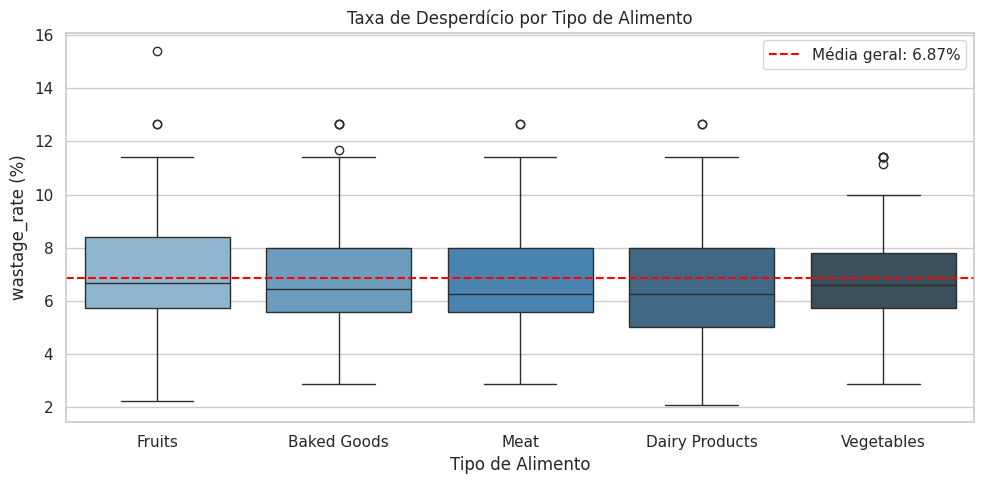

                count   mean  median    std
type_of_food                               
Baked Goods       366  6.859   6.439  2.010
Dairy Products    348  6.844   6.250  2.073
Fruits            303  6.997   6.667  2.085
Meat              398  6.845   6.250  2.002
Vegetables        203  6.764   6.571  1.811


In [15]:
# Taxa de desperdício por tipo de alimento
fig, ax = plt.subplots(figsize=(10, 5))

order_food = df.groupby('type_of_food', observed=True)['wastage_rate'].mean().sort_values(ascending=False).index
sns.boxplot(data=df, x='type_of_food', y='wastage_rate', order=order_food, palette='Blues_d', ax=ax)
ax.axhline(df['wastage_rate'].mean(), color='red', linestyle='--',
           label=f'Média geral: {df["wastage_rate"].mean():.2f}%')
ax.set_title('Taxa de Desperdício por Tipo de Alimento')
ax.set_xlabel('Tipo de Alimento')
ax.set_ylabel('wastage_rate (%)')
ax.legend()

plt.tight_layout()
plt.show()

print(df.groupby('type_of_food', observed=True)['wastage_rate']
      .agg(['count','mean','median','std']).round(3))

**Interpretação:** As médias por tipo de alimento são muito próximas entre si (variando de 6,76% para Vegetais a 7,00% para Frutas), e os boxplots mostram distribuições bastante sobrepostas. O tipo de alimento, por si só, não parece ser um discriminador forte do nível de desperdício — o efeito relevante parece emergir da interação com o método de armazenamento (como observado anteriormente para Baked Goods e Dairy).

### 6.2 Q2 — Tipo e Porte do Evento vs. Desperdício

Esta seção investiga se diferentes tipos de evento e portes (número de convidados) estão associados a diferentes padrões de desperdício.

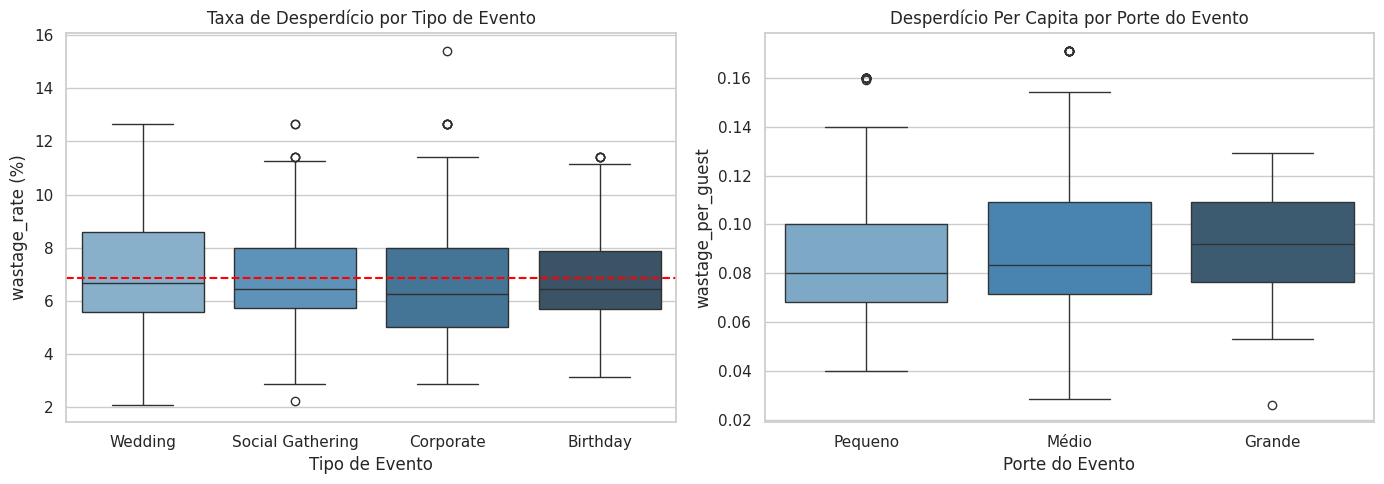

=== Desperdício por tipo de evento ===
                  count   mean  median
event_type                            
Birthday            332  6.818   6.439
Corporate           463  6.823   6.250
Social Gathering    417  6.866   6.439
Wedding             406  6.956   6.667

=== Desperdício per capita por porte ===
            count   mean  median
event_size                      
Grande        405  0.092   0.092
Médio         808  0.089   0.083
Pequeno       405  0.088   0.080


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Desperdício por tipo de evento
order_evt = df.groupby('event_type', observed=True)['wastage_rate'].mean().sort_values(ascending=False).index
sns.boxplot(data=df, x='event_type', y='wastage_rate', order=order_evt,
            ax=axes[0], palette='Blues_d')
axes[0].axhline(df['wastage_rate'].mean(), color='red', linestyle='--')
axes[0].set_title('Taxa de Desperdício por Tipo de Evento')
axes[0].set_xlabel('Tipo de Evento')
axes[0].set_ylabel('wastage_rate (%)')

# Desperdício per capita por porte
order_size = ['Pequeno', 'Médio', 'Grande']
sns.boxplot(data=df, x='event_size', y='wastage_per_guest', order=order_size,
            ax=axes[1], palette='Blues_d')
axes[1].set_title('Desperdício Per Capita por Porte do Evento')
axes[1].set_xlabel('Porte do Evento')
axes[1].set_ylabel('wastage_per_guest')

plt.tight_layout()
plt.show()

print("=== Desperdício por tipo de evento ===")
print(df.groupby('event_type', observed=True)['wastage_rate']
      .agg(['count','mean','median']).round(3))

print("\n=== Desperdício per capita por porte ===")
print(df.groupby('event_size', observed=True)['wastage_per_guest']
      .agg(['count','mean','median']).round(4))

**Interpretação:** O tipo de evento apresenta diferenças pequenas nas médias de desperdício: Wedding lidera levemente (6,96%), seguido por Social Gathering (6,87%), Corporate (6,82%) e Birthday (6,82%). As distribuições são amplamente sobrepostas, sugerindo que o tipo de evento, isoladamente, tem baixo poder discriminante para o nível de desperdício.

Quanto ao porte, o desperdício per capita é muito similar entre os três grupos: Pequeno (0,088), Médio (0,089) e Grande (0,092). A diferença existente é pequena e não segue um padrão linear claro (eventos grandes não desperdiçam consistentemente mais por pessoa), o que contradiz a hipótese H1 de Q2.

Essas diferenças, por tipo de evento e por porte, também são exploratórias: nenhuma delas foi avaliada por teste de significância estatística, o que reforça a leitura de baixo poder discriminante apenas em caráter descritivo.

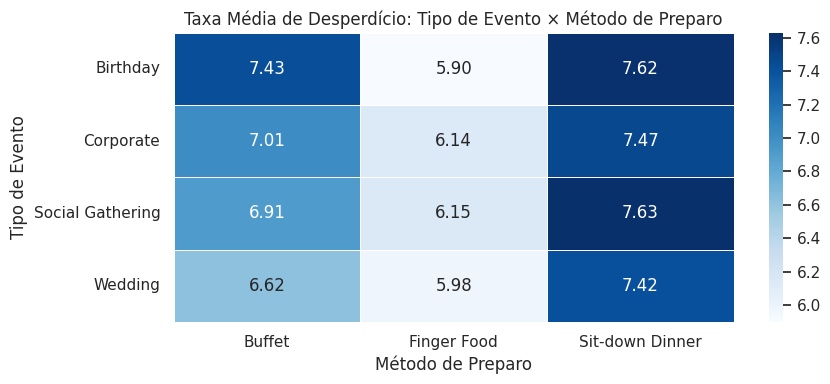

preparation_method,Buffet,Finger Food,Sit-down Dinner
event_type,,,
Birthday,7.43,5.90,7.62
Corporate,7.01,6.14,7.47
Social Gathering,6.91,6.15,7.63
Wedding,6.62,5.98,7.42


In [17]:
# Tabela cruzada: tipo de evento × método de preparo
ct_evt_prep = df.pivot_table(values='wastage_rate', index='event_type',
                              columns='preparation_method', aggfunc='mean').round(2)

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(ct_evt_prep, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5, ax=ax)
ax.set_title('Taxa Média de Desperdício: Tipo de Evento × Método de Preparo')
ax.set_xlabel('Método de Preparo')
ax.set_ylabel('Tipo de Evento')
plt.tight_layout()
plt.show()

display(ct_evt_prep)

**Interpretação:** O heatmap revela que a interação entre tipo de evento e método de preparo produz padrões mais interessantes do que cada variável isolada. Em todos os tipos de evento, Sit-down Dinner apresenta maior taxa de desperdício (~7,4–7,6%) e Finger Food a menor (~5,9–6,2%). Ou seja, o efeito do método de preparo persiste independentemente do tipo de evento, reforçando sua relevância para Q1 e Q4.

### 6.3 Q3 — Quantidade Produzida, Faixa de Preço e Taxa de Desperdício

Esta seção investiga se maior volume de produção ou preços mais altos estão associados a maior taxa de desperdício.

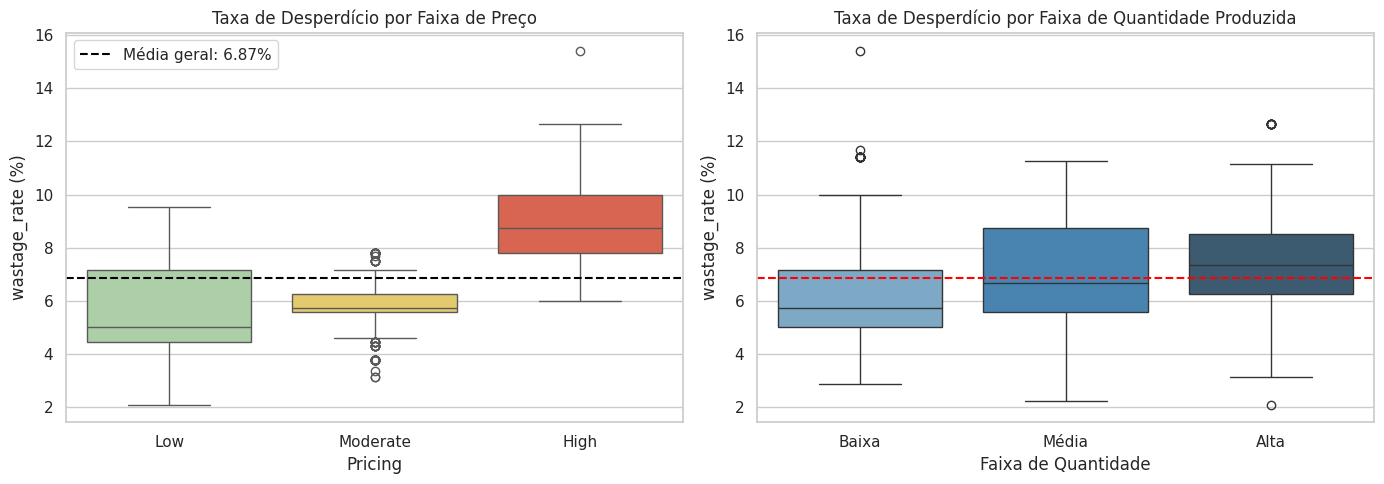

=== Taxa de desperdício por pricing ===
          count   mean  median    std
pricing                              
High        612  8.808   8.750  1.479
Low         410  5.463   5.000  1.534
Moderate    596  5.838   5.714  0.915

=== Taxa de desperdício por quantity_tier ===
               count   mean  median    std
quantity_tier                             
Alta             448  7.540   7.362  2.001
Baixa            538  6.283   5.714  1.941
Média            632  6.885   6.667  1.926


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Taxa de desperdício por pricing
order_price = ['Low', 'Moderate', 'High']
sns.boxplot(data=df, x='pricing', y='wastage_rate', order=order_price,
            ax=axes[0], palette=['#a8d5a2','#f6d55c','#ed553b'])
axes[0].axhline(df['wastage_rate'].mean(), color='black', linestyle='--',
                label=f'Média geral: {df["wastage_rate"].mean():.2f}%')
axes[0].set_title('Taxa de Desperdício por Faixa de Preço')
axes[0].set_xlabel('Pricing')
axes[0].set_ylabel('wastage_rate (%)')
axes[0].legend()

# Taxa por quantity_tier
order_qty = ['Baixa','Média','Alta']
sns.boxplot(data=df, x='quantity_tier', y='wastage_rate', order=order_qty,
            ax=axes[1], palette='Blues_d')
axes[1].axhline(df['wastage_rate'].mean(), color='red', linestyle='--')
axes[1].set_title('Taxa de Desperdício por Faixa de Quantidade Produzida')
axes[1].set_xlabel('Faixa de Quantidade')
axes[1].set_ylabel('wastage_rate (%)')

plt.tight_layout()
plt.show()

print("=== Taxa de desperdício por pricing ===")
print(df.groupby('pricing', observed=True)['wastage_rate']
      .agg(['count','mean','median','std']).round(3))
print("\n=== Taxa de desperdício por quantity_tier ===")
print(df.groupby('quantity_tier', observed=True)['wastage_rate']
      .agg(['count','mean','median','std']).round(3))

**Interpretação:** A faixa de preço é a variável com maior poder discriminante observado até aqui. Eventos de precificação **High** têm taxa média de desperdício de 8,8% — quase 60% superior à média de eventos **Low** (5,5%) e 50% acima de **Moderate** (5,8%). Além disso, a distribuição de High é mais dispersa (desvio padrão de 1,5), sugerindo maior variabilidade entre eventos de alto preço.

A quantidade produzida também mostra padrão claro: eventos com quantidade **Alta** têm taxa média de 7,5% vs. 6,3% para quantidade **Baixa** — diferença de 1,2 p.p. Ambas as variáveis sustentam as hipóteses H1 e H2 de Q3.

Embora expressivas, essas diferenças permanecem no nível descritivo; a confirmação por teste de hipótese estatística é recomendada como etapa posterior antes de sustentar qualquer decisão operacional baseada em pricing ou quantidade produzida.

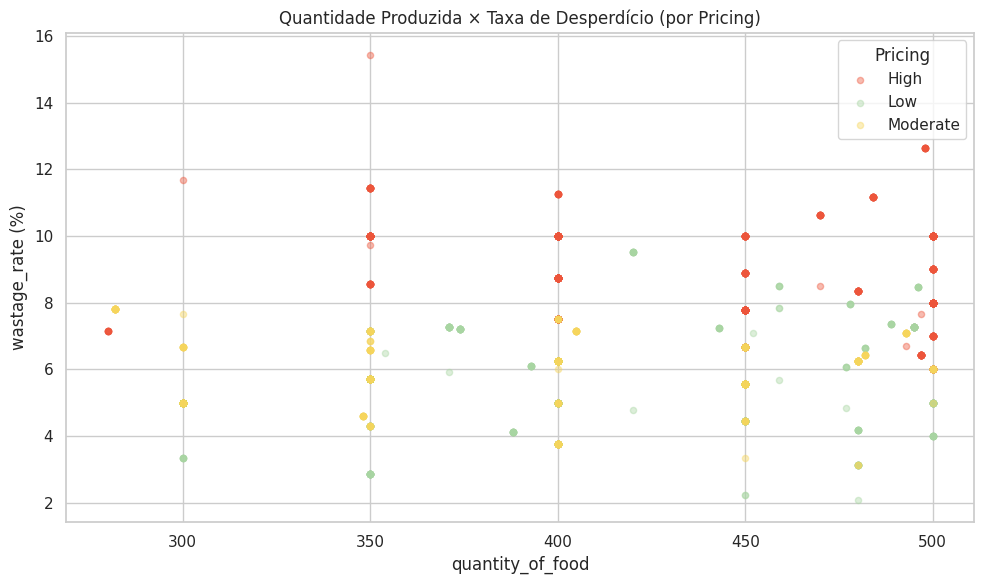

Correlação linear entre quantity_of_food e wastage_rate: 0.249


In [19]:
# Dispersão: quantity_of_food vs wastage_rate, colorido por pricing
fig, ax = plt.subplots(figsize=(10, 6))

palette = {'Low': '#a8d5a2', 'Moderate': '#f6d55c', 'High': '#ed553b'}
for pricing_val, group in df.groupby('pricing', observed=True):
    ax.scatter(group['quantity_of_food'], group['wastage_rate'],
               label=pricing_val, alpha=0.4, s=20, color=palette[pricing_val])

ax.set_title('Quantidade Produzida × Taxa de Desperdício (por Pricing)')
ax.set_xlabel('quantity_of_food')
ax.set_ylabel('wastage_rate (%)')
ax.legend(title='Pricing')
plt.tight_layout()
plt.show()

corr_qty_waste = df['quantity_of_food'].corr(df['wastage_rate'])
print(f"Correlação linear entre quantity_of_food e wastage_rate: {corr_qty_waste:.3f}")

**Interpretação:** O gráfico de dispersão revela uma estrutura importante: os pontos dos três grupos de pricing estão claramente separados em faixas horizontais distintas da taxa de desperdício. Eventos High concentram-se acima de 6%, enquanto Low e Moderate concentram-se abaixo. Dentro de cada grupo de pricing, há alguma tendência positiva entre quantidade produzida e taxa de desperdício, mas o efeito mais forte é claramente o da precificação. A correlação linear entre `quantity_of_food` e `wastage_rate` (≈0,25) é fraca globalmente, mas o padrão por pricing é mais estruturado do que sugere esse número.

### 6.4 Correlações entre Variáveis Numéricas

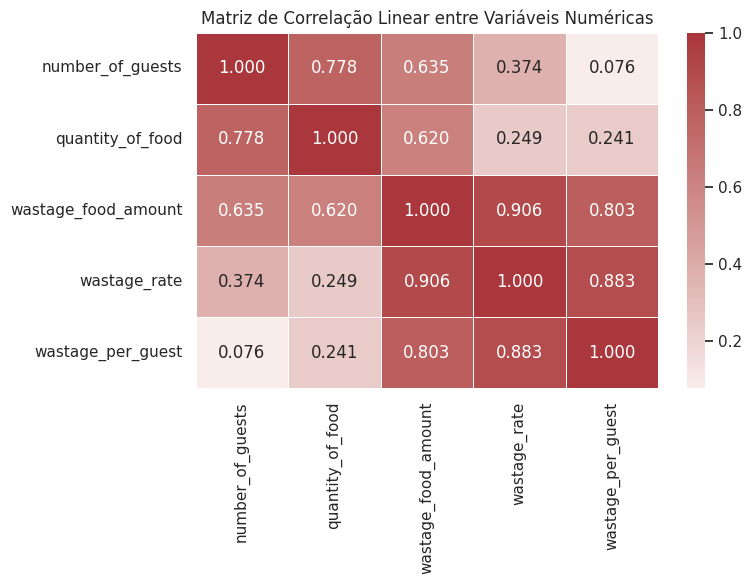

,number_of_guests,quantity_of_food,wastage_food_amount,wastage_rate,wastage_per_guest
number_of_guests,1.000,0.778,0.635,0.374,0.076
quantity_of_food,0.778,1.000,0.620,0.249,0.241
wastage_food_amount,0.635,0.620,1.000,0.906,0.803
wastage_rate,0.374,0.249,0.906,1.000,0.883
wastage_per_guest,0.076,0.241,0.803,0.883,1.000


In [20]:
num_corr = ['number_of_guests', 'quantity_of_food', 'wastage_food_amount',
             'wastage_rate', 'wastage_per_guest']

corr_matrix = df[num_corr].corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='vlag', center=0,
            linewidths=0.5, ax=ax)
ax.set_title('Matriz de Correlação Linear entre Variáveis Numéricas')
plt.tight_layout()
plt.show()

display(corr_matrix.round(3))

**Interpretação:** As correlações mais relevantes são:

- **`wastage_food_amount` × `wastage_rate`** (0,906): correlação forte esperada, pois `wastage_rate` é derivada de `wastage_food_amount` — não indica independência analítica.

- **`wastage_rate` × `wastage_per_guest`** (0,883): ambas capturam dimensões similares do desperdício, confirmando coerência interna das variáveis derivadas.

- **`quantity_of_food` × `number_of_guests`** (0,778): eventos maiores tendem a produzir mais alimentos, uma relação operacional esperada.

- **`number_of_guests` × `wastage_rate`** (0,374): correlação moderada-fraca, sugerindo que o número de convidados tem alguma associação com a taxa de desperdício, mas não é o fator principal.

Nenhuma das correlações isoladas é suficientemente forte para explicar o desperdício sem considerar variáveis contextuais como pricing e método de preparo.

### 6.5 Q4 — Perfis de Evento e Ranking de Risco

Esta seção combina porte, método de preparo e pricing para identificar quais combinações operacionais concentram os maiores níveis de desperdício.

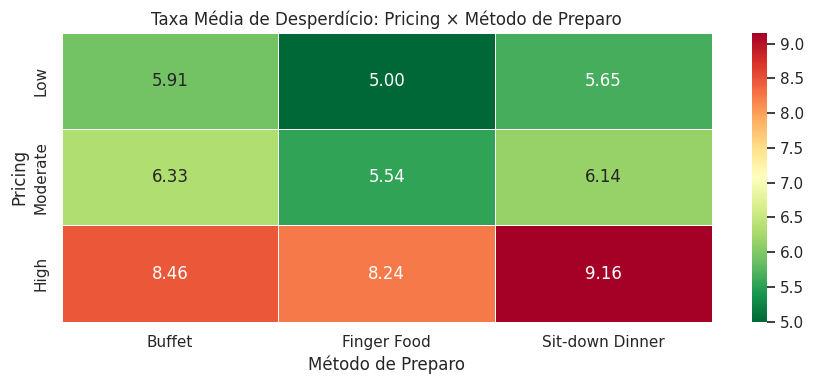

preparation_method,Buffet,Finger Food,Sit-down Dinner
pricing,,,
Low,5.91,5.00,5.65
Moderate,6.33,5.54,6.14
High,8.46,8.24,9.16


In [21]:
# Taxa por pricing × preparation_method
ct_price_prep = df.pivot_table(values='wastage_rate', index='pricing',
                                columns='preparation_method', aggfunc='mean')
ct_price_prep = ct_price_prep.loc[['Low','Moderate','High']]

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(ct_price_prep, annot=True, fmt='.2f', cmap='RdYlGn_r',
            linewidths=0.5, ax=ax)
ax.set_title('Taxa Média de Desperdício: Pricing × Método de Preparo')
ax.set_xlabel('Método de Preparo')
ax.set_ylabel('Pricing')
plt.tight_layout()
plt.show()

display(ct_price_prep.round(2))

**Interpretação:** O heatmap revela o padrão mais estruturado da análise: a **interação entre pricing e método de preparo** produz variações expressivas na taxa de desperdício. A célula de maior risco é **High × Sit-down Dinner** (9,16%), enquanto a célula de menor risco é **Low × Finger Food** (5,00%). A diferença entre os extremos é de 4,16 p.p. — mais de 80% de diferença relativa em relação ao menor valor. Dentro de cada linha de pricing, Sit-down Dinner é sempre o método com maior taxa de desperdício, e Finger Food o menor. A hierarquia dos métodos de preparo se mantém robusta em todos os níveis de preço.

Assim como nas demais análises de grupo desta AED, trata-se de um padrão descritivo, ainda sem verificação de significância estatística para a interação observada.

In [22]:
# Top e bottom perfis por taxa média de desperdício
perfis = (df.groupby('event_profile', observed=True)['wastage_rate']
          .agg(['mean','count'])
          .reset_index()
          .rename(columns={'mean':'taxa_media','count':'n_eventos'})
          .sort_values('taxa_media', ascending=False))

print("=== Top 8 Perfis — Maior Taxa de Desperdício ===")
display(perfis.head(8).round(3))

print("\n=== Bottom 5 Perfis — Menor Taxa de Desperdício ===")
display(perfis.tail(5).round(3))

=== Top 8 Perfis — Maior Taxa de Desperdício ===


,event_profile,taxa_media,n_eventos
23,Pequeno | Sit-down Dinner | High,11.143,18
14,Médio | Sit-down Dinner | High,9.100,160
5,Grande | Sit-down Dinner | High,9.003,176
20,Pequeno | Finger Food | High,8.740,32
8,Médio | Buffet | High,8.644,94
11,Médio | Finger Food | High,8.514,54
17,Pequeno | Buffet | High,8.000,5
1,Grande | Buffet | Low,7.976,26



=== Bottom 5 Perfis — Menor Taxa de Desperdício ===


,event_profile,taxa_media,n_eventos
15,Médio | Sit-down Dinner | Low,5.153,45
12,Médio | Finger Food | Low,5.088,111
24,Pequeno | Sit-down Dinner | Low,5.056,53
21,Pequeno | Finger Food | Low,4.766,44
18,Pequeno | Buffet | Low,2.971,25


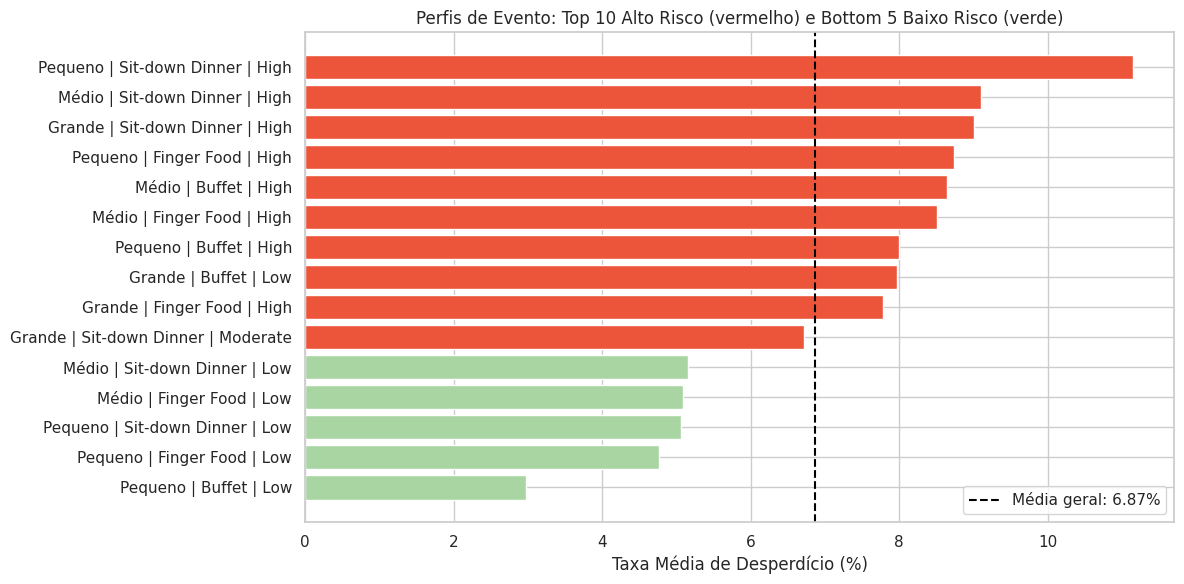

In [23]:
# Visualização dos perfis de risco (top 10 e bottom 5)
top_bottom = pd.concat([perfis.head(10), perfis.tail(5)])
cores = ['#ed553b'] * 10 + ['#a8d5a2'] * 5

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(top_bottom['event_profile'], top_bottom['taxa_media'],
               color=cores, edgecolor='white')
ax.axvline(df['wastage_rate'].mean(), color='black', linestyle='--',
           label=f'Média geral: {df["wastage_rate"].mean():.2f}%')
ax.set_title('Perfis de Evento: Top 10 Alto Risco (vermelho) e Bottom 5 Baixo Risco (verde)')
ax.set_xlabel('Taxa Média de Desperdício (%)')
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

**Interpretação:** O perfil de maior risco é **Pequeno | Sit-down Dinner | High** (taxa média ≈ 11,1%), enquanto o de menor risco é **Pequeno | Buffet | Low** (≈ 3,0%). É notável que eventos **pequenos com Sit-down Dinner e pricing High** apresentem o maior desperdício — possivelmente porque esses eventos têm menor flexibilidade para ajustar porções individualmente sem comprometer a formalidade do formato. A combinação de **pricing High com qualquer método de preparo** consistentemente aparece no topo do ranking de risco, confirmando pricing como o fator mais associado ao desperdício neste dataset.

Vale reforçar que este ranking é exploratório: vários perfis têm poucos registros (ver Seção 7.4), o que torna suas médias menos estáveis e reforça a necessidade de validação estatística antes de qualquer uso operacional.

## 7. Padrões, Tendências e Anomalias Exploratórias

### 7.1 Padrão Central: Pricing como Fator Dominante

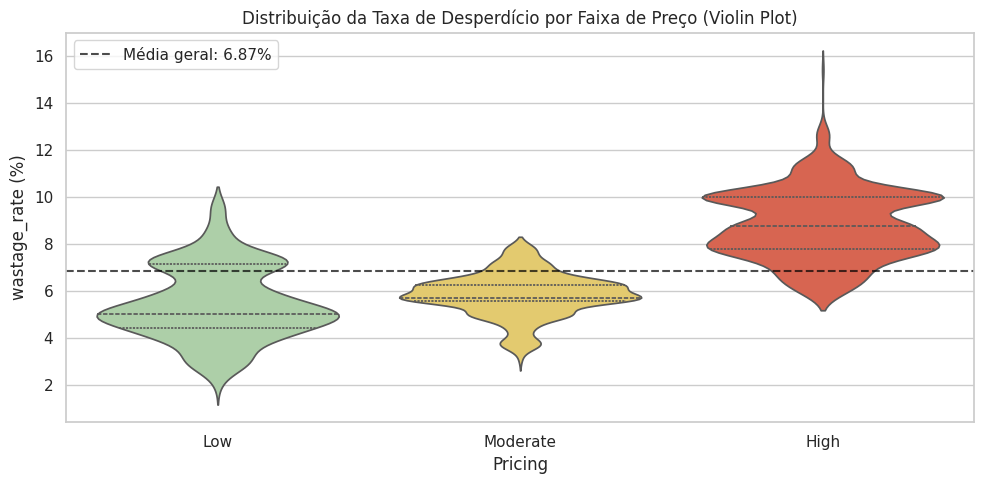

In [24]:
# Distribuição completa da wastage_rate por pricing — violin plot
fig, ax = plt.subplots(figsize=(10, 5))
order_price = ['Low','Moderate','High']
sns.violinplot(data=df, x='pricing', y='wastage_rate', order=order_price,
               palette=['#a8d5a2','#f6d55c','#ed553b'], inner='quartile', ax=ax)
ax.axhline(df['wastage_rate'].mean(), color='black', linestyle='--', alpha=0.7,
           label=f'Média geral: {df["wastage_rate"].mean():.2f}%')
ax.set_title('Distribuição da Taxa de Desperdício por Faixa de Preço (Violin Plot)')
ax.set_xlabel('Pricing')
ax.set_ylabel('wastage_rate (%)')
ax.legend()
plt.tight_layout()
plt.show()

**Padrão observado:** O violin plot confirma que a faixa de preço não apenas altera a média mas muda estruturalmente a forma da distribuição. **Low** e **Moderate** têm distribuições concentradas em torno de 5–6%, com caudas curtas. **High** tem distribuição mais espalhada, deslocada para valores acima de 7%, com cauda que se estende até ~15%. Este é o padrão mais consistente e relevante do dataset.

### 7.2 Padrão Secundário: Hierarquia Estável do Método de Preparo

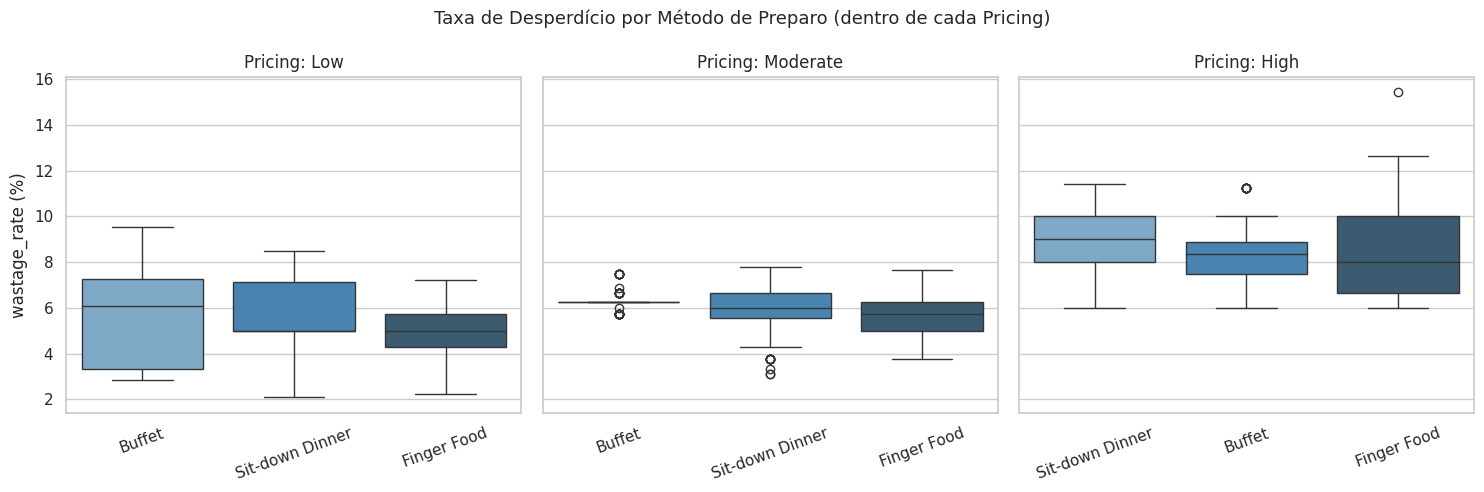

In [25]:
# Consistência do efeito de preparation_method em cada pricing
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, price in zip(axes, ['Low','Moderate','High']):
    sub = df[df['pricing'] == price]
    order_pm = sub.groupby('preparation_method', observed=True)['wastage_rate'].mean().sort_values(ascending=False).index
    sns.boxplot(data=sub, x='preparation_method', y='wastage_rate',
                order=order_pm, palette='Blues_d', ax=ax)
    ax.set_title(f'Pricing: {price}')
    ax.set_xlabel('')
    if ax == axes[0]:
        ax.set_ylabel('wastage_rate (%)')
    ax.tick_params(axis='x', rotation=20)

plt.suptitle('Taxa de Desperdício por Método de Preparo (dentro de cada Pricing)', fontsize=13)
plt.tight_layout()
plt.show()

**Padrão observado:** A hierarquia Sit-down Dinner > Buffet > Finger Food (em termos de taxa de desperdício) se mantém dentro de cada faixa de preço. Essa consistência reforça que o efeito do método de preparo é robusto e não é um artefato do pricing. Os dois fatores parecem agir de forma aditiva sobre o desperdício.

### 7.3 Anomalia: Efeito do Armazenamento Condicionado ao Tipo de Alimento

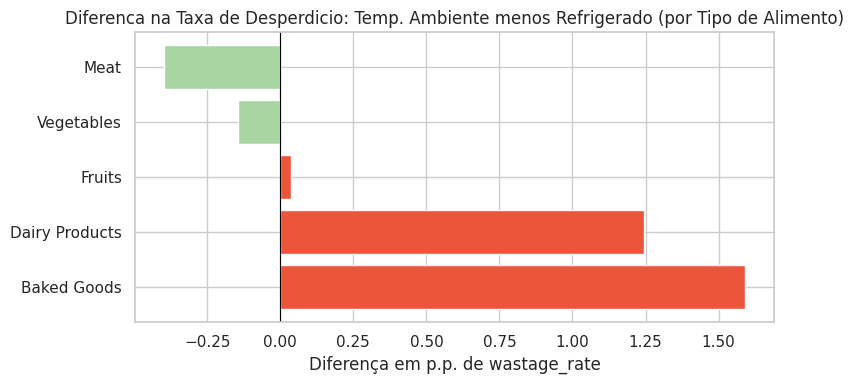

storage_conditions,Refrigerated,Room Temperature,diferenca
type_of_food,,,
Baked Goods,5.278,6.868,1.590
Dairy Products,5.619,6.865,1.246
Fruits,6.973,7.010,0.037
Vegetables,6.794,6.649,-0.145
Meat,6.935,6.537,-0.397


In [26]:
# Diferença de desperdício (Temp. Ambiente - Refrigerado) por tipo de alimento
diff_storage = (df.pivot_table(values='wastage_rate', index='type_of_food',
                                columns='storage_conditions', aggfunc='mean')
                .assign(diferenca=lambda x: x['Room Temperature'] - x['Refrigerated'])
                .sort_values('diferenca', ascending=False))

fig, ax = plt.subplots(figsize=(8, 4))
cores = ['#ed553b' if v > 0 else '#a8d5a2' for v in diff_storage['diferenca']]
ax.barh(diff_storage.index, diff_storage['diferenca'], color=cores, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Diferenca na Taxa de Desperdicio: Temp. Ambiente menos Refrigerado (por Tipo de Alimento)')
ax.set_xlabel('Diferença em p.p. de wastage_rate')
plt.tight_layout()
plt.show()

display(diff_storage[['Refrigerated','Room Temperature','diferenca']].round(3))

**Anomalia observada:** O efeito do armazenamento é claramente assimétrico entre tipos de alimento. **Baked Goods** e **Dairy Products** têm diferença positiva expressiva (+1,6 p.p. e +1,25 p.p. respectivamente) — ou seja, armazenamento em temperatura ambiente está associado a muito mais desperdício nesses itens. Já **Meat** e **Vegetables** mostram diferença negativa (refrigeração está associada a mais desperdício nesses itens — padrão inesperado que pode refletir particularidades dos eventos ou volume das categorias). Essa heterogeneidade sugere que analisar armazenamento de forma agregada mascara dinâmicas importantes por tipo de alimento.

### 7.4 Padrão de Concentração: Distribuição Desigual dos Métodos

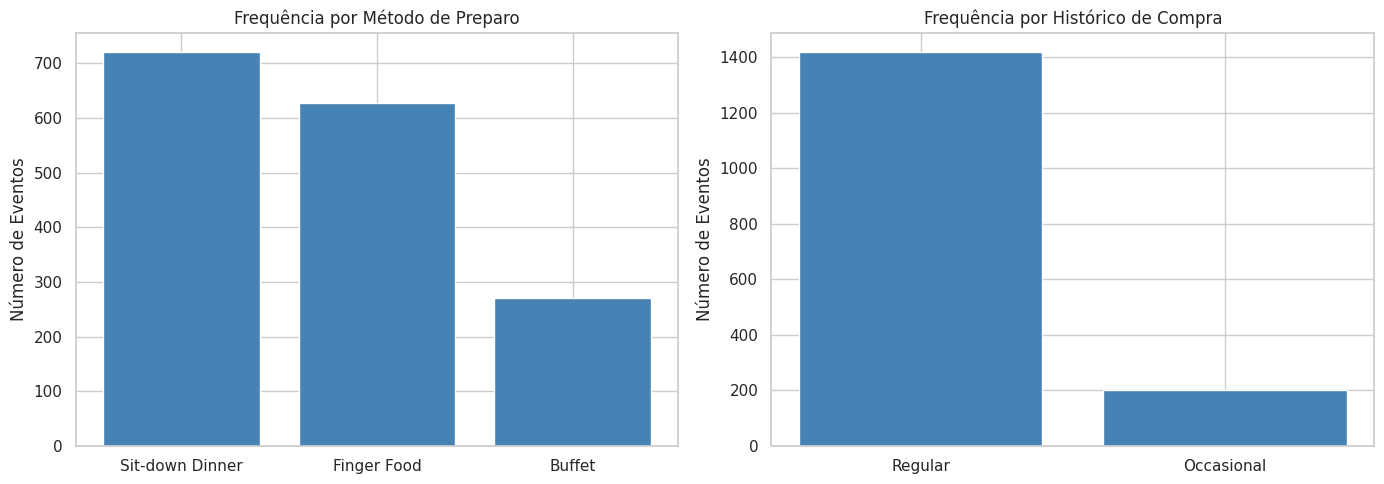

Buffet representa apenas 16.7 % dos eventos
Occasional representa apenas 12.4 % dos eventos


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Frequência dos métodos de preparo
freq_pm = df['preparation_method'].value_counts()
axes[0].bar(freq_pm.index, freq_pm.values, color='steelblue', edgecolor='white')
axes[0].set_title('Frequência por Método de Preparo')
axes[0].set_ylabel('Número de Eventos')

# Frequência de compra
freq_ph = df['purchase_history'].value_counts()
axes[1].bar(freq_ph.index, freq_ph.values, color='steelblue', edgecolor='white')
axes[1].set_title('Frequência por Histórico de Compra')
axes[1].set_ylabel('Número de Eventos')

plt.tight_layout()
plt.show()

print("Buffet representa apenas", round(freq_pm['Buffet']/len(df)*100,1), "% dos eventos")
print("Occasional representa apenas", round(freq_ph['Occasional']/len(df)*100,1), "% dos eventos")

**Padrão de concentração:** O método Buffet é o menos representado (16,7% dos eventos), e a categoria Occasional em `purchase_history` é ainda mais escassa (12,4%). Comparações envolvendo esses grupos têm menos estabilidade estatística. Este é um ponto de atenção para análises futuras: conclusões sobre Buffet e Occasional devem ser interpretadas com cautela.

## 8. Formulação de Hipóteses Exploratórias

Cada hipótese a seguir está vinculada a uma evidência específica observada na AED, associada a uma pergunta investigável do projeto. As hipóteses são formulações exploratórias e provisórias — não são afirmações causais. Todas as diferenças descritivas que sustentam essas hipóteses foram observadas sem testes de significância estatística; etapas posteriores do pipeline deverão aplicar métodos analíticos mais rigorosos (testes de hipótese, controle de confundidores, modelagem) antes que qualquer uma delas seja tratada como conclusão validada.

In [28]:
hipoteses = pd.DataFrame([
    {
        'ID': 'HE-01',
        'Questão': 'Q1',
        'Evidência observada': (
            'Sit-down Dinner tem taxa média de desperdício de 7,5% vs. 6,1% de Finger Food '
            '(diferença de ~23% relativa). A hierarquia persiste dentro de todos os níveis de pricing.'
        ),
        'Hipótese exploratória': (
            'Eventos em formato Sit-down Dinner estão associados a maior taxa de desperdício '
            'em comparação com Finger Food, possivelmente devido à rigidez no planejamento '
            'de porções individuais nesse formato.'
        ),
        'Cuidado': 'Não implica que Sit-down Dinner cause desperdício; outros fatores confundidores podem estar presentes.'
    },
    {
        'ID': 'HE-02',
        'Questão': 'Q1',
        'Evidência observada': (
            'Para Baked Goods e Dairy Products, armazenamento em temperatura ambiente está '
            'associado a taxa ~1,5 p.p. maior do que refrigerado. Para Meat e Vegetais, '
            'o padrão é invertido ou neutro.'
        ),
        'Hipótese exploratória': (
            'O efeito das condições de armazenamento sobre o desperdício é condicionado ao '
            'tipo de alimento: alimentos perecíveis processados (Baked Goods, Dairy) podem '
            'ser mais sensíveis à temperatura de armazenamento do que carnes e vegetais.'
        ),
        'Cuidado': 'O resultado oposto para Meat é inesperado e pode refletir características da amostra — requer investigação.'
    },
    {
        'ID': 'HE-03',
        'Questão': 'Q3',
        'Evidência observada': (
            'Eventos com pricing High têm taxa média de desperdício de 8,8%, contra 5,5% '
            'para Low — diferença de 3,3 p.p. (~60% maior). O padrão é consistente e '
            'a distribuição de High é mais dispersa e deslocada para cima.'
        ),
        'Hipótese exploratória': (
            'Eventos de maior faixa de preço estão associados a taxas de desperdício '
            'substancialmente mais altas. Isso pode estar relacionado a expectativas '
            'de abundância, menor incentivo ao controle de produção em eventos premium, '
            'ou cardápios mais elaborados com menor flexibilidade de ajuste.'
        ),
        'Cuidado': 'Pricing pode ser um proxy de outros fatores (tipo de evento, cardápio, público) que explicam o desperdício.'
    },
    {
        'ID': 'HE-04',
        'Questão': 'Q3',
        'Evidência observada': (
            'Eventos com quantidade produzida Alta têm taxa média de 7,5% vs. 6,3% '
            'para quantidade Baixa — diferença de 1,2 p.p.'
        ),
        'Hipótese exploratória': (
            'Maior volume de produção está associado a maior proporção de desperdício, '
            'sugerindo que o planejamento de produção pode ter menor precisão à medida '
            'que a escala do evento aumenta.'
        ),
        'Cuidado': 'A correlação linear entre quantity_of_food e wastage_rate é apenas 0,25 — o efeito é moderado.'
    },
    {
        'ID': 'HE-05',
        'Questão': 'Q4',
        'Evidência observada': (
            'O perfil "Pequeno | Sit-down Dinner | High" apresenta taxa média de 11,1%, '
            'o mais elevado entre todos os 27 perfis. Perfis com pricing High e Sit-down Dinner '
            'consistentemente ocupam as posições superiores no ranking de risco.'
        ),
        'Hipótese exploratória': (
            'A combinação de pricing High com Sit-down Dinner representa o perfil operacional '
            'de maior risco de desperdício, independentemente do porte do evento. '
            'Ações preventivas concentradas nesse perfil podem ter maior impacto na redução '
            'total do desperdício.'
        ),
        'Cuidado': (
            'Alguns perfis têm poucos registros, tornando suas médias instáveis. '
            'O ranking deve ser validado com maior volume de dados por perfil.'
        )
    },
    {
        'ID': 'HE-06',
        'Questão': 'Q2',
        'Evidência observada': (
            'As médias de desperdício per capita são similares entre portes '
            '(Pequeno: 0,088, Médio: 0,089, Grande: 0,092), sem padrão linear claro.'
        ),
        'Hipótese exploratória': (
            'O porte do evento, medido pelo número de convidados, não é um preditor '
            'relevante do desperdício per capita quando analisado de forma isolada. '
            'O efeito do porte pode estar subordinado ao método de preparo e ao pricing.'
        ),
        'Cuidado': 'Ausência de efeito univariado não descarta interação com outras variáveis — necessário investigar combinações.'
    },
])

for _, row in hipoteses.iterrows():
    print(f"{'─'*80}")
    print(f"[{row['ID']}] Questão: {row['Questão']}")
    print(f"Evidência: {row['Evidência observada']}")
    print(f"Hipótese: {row['Hipótese exploratória']}")
    print(f"Cuidado: {row['Cuidado']}")
print('─'*80)

────────────────────────────────────────────────────────────────────────────────
[HE-01] Questão: Q1
Evidência: Sit-down Dinner tem taxa média de desperdício de 7,5% vs. 6,1% de Finger Food (diferença de ~23% relativa). A hierarquia persiste dentro de todos os níveis de pricing.
Hipótese: Eventos em formato Sit-down Dinner estão associados a maior taxa de desperdício em comparação com Finger Food, possivelmente devido à rigidez no planejamento de porções individuais nesse formato.
Cuidado: Não implica que Sit-down Dinner cause desperdício; outros fatores confundidores podem estar presentes.
────────────────────────────────────────────────────────────────────────────────
[HE-02] Questão: Q1
Evidência: Para Baked Goods e Dairy Products, armazenamento em temperatura ambiente está associado a taxa ~1,5 p.p. maior do que refrigerado. Para Meat e Vegetais, o padrão é invertido ou neutro.
Hipótese: O efeito das condições de armazenamento sobre o desperdício é condicionado ao tipo de alimento:

## 9. Síntese Final Interpretativa

Esta seção organiza as principais conclusões da AED distinguindo três dimensões, para evitar transformar padrões descritivos em conclusões causais: a **evidência observada** (o que foi efetivamente medido nos dados), a **hipótese exploratória derivada** (a interpretação provisória proposta a partir da evidência) e a **limitação** (o que impede tratar essa hipótese como conclusão definitiva).

**1. Faixa de preço (`pricing`)**
- *Evidência observada:* eventos com pricing High têm taxa média de desperdício de 8,8%, cerca de 60% superior à média de eventos Low (5,5%); a distribuição de High também é mais dispersa e deslocada para valores mais altos (Seção 7.1).
- *Hipótese exploratória:* características associadas a eventos de maior faixa de preço (cardápios mais elaborados, menor rigor no controle de produção, maior expectativa de fartura) estão relacionadas a um desperdício proporcionalmente maior.
- *Limitação:* a diferença é descritiva; pricing pode ser um proxy de outras variáveis não medidas (tipo de cardápio, perfil do cliente), e nenhum teste estatístico de significância foi aplicado.

**2. Método de preparo (`preparation_method`)**
- *Evidência observada:* Sit-down Dinner apresenta taxa de desperdício sistematicamente maior do que Finger Food (~7,5% vs. ~6,1%), hierarquia que se mantém em todos os níveis de pricing e tipos de evento (Seções 6.1 e 6.2).
- *Hipótese exploratória:* formatos de serviço com maior rigidez no planejamento de porções individuais (Sit-down Dinner) favorecem maior desperdício do que formatos mais flexíveis (Finger Food).
- *Limitação:* a robustez da hierarquia entre subgrupos reforça a plausibilidade do padrão, mas não substitui um teste formal de significância nem controla por outros fatores atuando simultaneamente.

**3. Efeito combinado pricing × método de preparo**
- *Evidência observada:* o perfil High × Sit-down Dinner concentra a maior taxa média de desperdício (9,16%), enquanto Low × Finger Food concentra a menor (5,00%) — diferença de 4,16 p.p. (Seção 6.5).
- *Hipótese exploratória:* pricing e método de preparo atuam de forma aditiva sobre o desperdício, de modo que a combinação dos dois fatores identifica os perfis operacionais de maior risco.
- *Limitação:* alguns perfis (sobretudo os que envolvem Buffet e a categoria Occasional de `purchase_history`) têm poucos registros, tornando suas médias menos estáveis (Seção 7.4).

**4. Condições de armazenamento (efeito condicionado ao tipo de alimento)**
- *Evidência observada:* armazenamento em temperatura ambiente está associado a maior desperdício apenas para Baked Goods e Dairy Products (~+1,5 p.p.); para Meat e Vegetables o padrão é neutro ou invertido (Seções 6.1 e 7.3).
- *Hipótese exploratória:* alimentos mais perecíveis ou processados são mais sensíveis à ausência de refrigeração do que carnes e vegetais.
- *Limitação:* o padrão invertido em Meat é inesperado e não é explicado pelas variáveis disponíveis; pode refletir particularidades da amostra e exige investigação com variáveis adicionais de contexto.

**5. Tipo de evento e porte**
- *Evidência observada:* as diferenças de desperdício médio entre tipos de evento e entre portes (pequeno/médio/grande) são pequenas e sem padrão linear claro (Seção 6.2).
- *Hipótese exploratória:* essas variáveis, isoladamente, têm baixo poder explicativo sobre o desperdício; seu efeito pode estar subordinado a pricing e método de preparo.
- *Limitação:* a ausência de efeito univariado não descarta interações não exploradas nesta AED.

**Limitações gerais da análise:**
- O dataset não contém variável temporal, o que impede a análise de tendências ao longo do tempo.
- Não há identificador único de evento, o que limita verificações de rastreabilidade individual.
- Todas as comparações entre grupos apresentadas nesta AED são descritivas; nenhum teste de significância estatística foi conduzido nesta etapa.
- As relações observadas são associações exploratórias — não há evidência causal estabelecida, e as hipóteses formuladas na Seção 8 deverão ser validadas com métodos inferenciais em etapas posteriores do pipeline de Ciência de Dados.